# ML Zoomcamp 2026 — Homework 8 (Neural Networks and Deep Learning)
**Nicolau Calado Jofilsan** · 2026 cohort (DataTalks.Club)

**EN.** A small PyTorch convolutional network that classifies photos of curly and straight hair. The 2026 reference setup
freezes the dataset (checksummed archive), framework versions, architecture, split, random seed and evaluation procedure,
so the numbers can be reproduced on a CPU. Phase 1 trains a baseline for 10 epochs; phase 2 keeps the same model and
optimizer and trains 10 more epochs with data augmentation, while the held-out evaluation images stay untouched.
Deadline: see the course platform (the cohort README lists Mon 23/11/2026, 23:00 UTC).

**PT.** Uma rede neural convolucional pequena em PyTorch que classifica fotos de cabelo cacheado e liso. O setup de
referência de 2026 fixa a base (arquivo com checksum), as versões das bibliotecas, a arquitetura, a divisão, a semente e o
procedimento de avaliação, de modo que os números podem ser reproduzidos em CPU. A fase 1 treina um modelo base por 10
épocas; a fase 2 mantém o mesmo modelo e otimizador e treina mais 10 épocas com data augmentation, enquanto as imagens de
avaliação permanecem intactas. Prazo: veja a plataforma do curso (o README da turma indica seg 23/11/2026, 23:00 UTC).

Topics / Conteúdo: loss for a single-logit classifier, parameter count, training/evaluation loop, overfitting, data
augmentation, reproducibility (seeds, deterministic algorithms).

## 0. Setup, data and reproducibility / Preparação, dados e reprodutibilidade

In [1]:
import hashlib
import json
import os
import platform
import random
import statistics
import time
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torchvision
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

%matplotlib inline

print("python:", platform.python_version(), "| torch:", torch.__version__, "| torchvision:", torchvision.__version__,
      "| numpy:", np.__version__)
if not torch.__version__.startswith("2.9"):
    print("NOTE: the reference run uses torch 2.9.0+cpu; other versions may shift the numbers slightly "
          "(see the notes at the end) / a referência usa torch 2.9.0+cpu; outras versões podem mudar um pouco os números.")

python: 3.11.18 | torch: 2.9.1 | torchvision: 0.24.0 | numpy: 2.3.3


**EN.** The archive is downloaded once and checked against the SHA-256 published in the homework before it is
extracted (a file that does not match the checksum is not used). **PT.** O arquivo é baixado uma vez e conferido com o
SHA-256 publicado no enunciado antes de ser extraído (um arquivo que não bate com o checksum não é usado).

In [2]:
DATA_URL = "https://github.com/SVizor42/ML_Zoomcamp/releases/download/straight-curly-data/data.zip"
EXPECTED_SHA256 = "9e53453e3017502f22860cb08558f0cdb343e102fb61feab75960616185e7d67"
ZIP_FILE, DATA_DIR = "data.zip", "data"

if not os.path.isdir(os.path.join(DATA_DIR, "train")):
    if not os.path.exists(ZIP_FILE):
        urllib.request.urlretrieve(DATA_URL, ZIP_FILE)
    digest = hashlib.sha256(open(ZIP_FILE, "rb").read()).hexdigest()
    assert digest == EXPECTED_SHA256, f"checksum mismatch: {digest}"
    with zipfile.ZipFile(ZIP_FILE) as zf:
        zf.extractall(".")
print("archive checksum OK / checksum do arquivo conferido:", EXPECTED_SHA256[:16] + "...")
print("folders / pastas:", sorted(os.listdir(DATA_DIR)))

archive checksum OK / checksum do arquivo conferido: 9e53453e3017502f...
folders / pastas: ['test', 'train']


**EN.** Seeds and deterministic algorithms are set **before** building datasets, loaders, model or optimizer. The
reference script also limits PyTorch to 2 CPU threads, which keeps the arithmetic order (and so the numbers) closer
from one machine to another. **PT.** As sementes e os algoritmos determinísticos são fixados **antes** de criar bases,
loaders, modelo e otimizador. O script de referência também limita o PyTorch a 2 threads de CPU, o que aproxima a ordem
das operações (e portanto os números) entre máquinas.

In [3]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.use_deterministic_algorithms(True)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.set_num_threads(2)

device = torch.device("cpu")
BATCH_SIZE = 20
EPOCHS_PER_PHASE = 10
NORMALIZE = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

evaluation_transform = transforms.Compose([
    transforms.Resize((200, 200), interpolation=transforms.InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    NORMALIZE,
])
train_transform_augmented = transforms.Compose([
    transforms.Resize((200, 200), interpolation=transforms.InterpolationMode.BILINEAR),
    transforms.RandomRotation(50, interpolation=transforms.InterpolationMode.NEAREST),
    transforms.RandomResizedCrop(200, scale=(0.9, 1.0), ratio=(0.9, 1.1),
                                 interpolation=transforms.InterpolationMode.BILINEAR),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    NORMALIZE,
])

train_dataset = datasets.ImageFolder(os.path.join(DATA_DIR, "train"), transform=evaluation_transform)
evaluation_dataset = datasets.ImageFolder(os.path.join(DATA_DIR, "test"), transform=evaluation_transform)

print("classes:", train_dataset.class_to_idx)
print("train images:", len(train_dataset), "| held-out evaluation images:", len(evaluation_dataset))
assert len(train_dataset) == 800 and len(evaluation_dataset) == 201
assert train_dataset.class_to_idx == {"curly": 0, "straight": 1}

classes: {'curly': 0, 'straight': 1}
train images: 800 | held-out evaluation images: 201


**EN.** The homework table says 800 training and 201 evaluation images; the archive has one extra GIF in the `curly`
training folder that `ImageFolder` ignores, which is why the counts match. The evaluation set is never augmented and no
new train/test split is made. **PT.** A tabela do enunciado diz 800 imagens de treino e 201 de avaliação; o arquivo tem um
GIF a mais na pasta `curly` do treino, que o `ImageFolder` ignora, e por isso as contagens batem. O conjunto de avaliação
nunca recebe augmentation e nenhuma nova divisão treino/teste é feita.

## Q1. Loss function / Função de perda

**EN.** The model (defined next) returns **one logit** per image, so the matching loss is the one that applies the
sigmoid and the binary cross-entropy together in a numerically stable way. A `sigmoid` is applied only when turning logits
into predictions. **PT.** O modelo (definido a seguir) devolve **um logit** por imagem, então a perda adequada é a que
aplica sigmoide e entropia cruzada binária juntas, de forma numericamente estável. A sigmoide só é usada ao transformar
logits em previsões.

In [4]:
class HairModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=0)
        self.pool = nn.MaxPool2d(kernel_size=2)
        self.hidden = nn.Linear(32 * 99 * 99, 64)
        self.output = nn.Linear(64, 1)

    def forward(self, x):
        x = self.pool(nn.functional.relu(self.conv(x)))
        x = x.flatten(start_dim=1)
        x = nn.functional.relu(self.hidden(x))
        return self.output(x)


model = HairModel().to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.002, momentum=0.8)
print("Q1 =", type(criterion).__name__)

Q1 = BCEWithLogitsLoss


**Answer / Resposta Q1: `nn.BCEWithLogitsLoss()`** — one output logit + binary labels. `MSELoss` would treat the
problem as regression, `CrossEntropyLoss` expects one logit per class (two outputs here), and `CosineEmbeddingLoss`
compares pairs of embeddings. / um logit de saída + rótulos binários. `MSELoss` trataria o problema como regressão,
`CrossEntropyLoss` espera um logit por classe (duas saídas aqui) e `CosineEmbeddingLoss` compara pares de embeddings.

## Q2. Number of trainable parameters / Número de parâmetros treináveis

In [5]:
total_params = sum(p.numel() for p in model.parameters())
print("Q2 =", f"{total_params:,}")

# the same number by hand, layer by layer / o mesmo número, camada a camada
conv = 3 * 32 * 3 * 3 + 32
hidden = (32 * 99 * 99) * 64 + 64
output = 64 * 1 + 1
print(f"conv {conv:,} + hidden {hidden:,} + output {output:,} = {conv + hidden + output:,}")
assert conv + hidden + output == total_params

Q2 = 20,073,473
conv 896 + hidden 20,072,512 + output 65 = 20,073,473


**Answer / Resposta Q2: 20073473.** The 3×3 convolution has 3·32·9 weights + 32 biases = 896. After the
convolution (198×198) and the 2×2 pooling the map is 99×99, so the hidden layer sees 32·99·99 = 313,632 inputs and holds
313,632·64 + 64 = 20,072,512 parameters, almost all of the model. The output layer adds 64 + 1 = 65. /
A convolução 3×3 tem 3·32·9 pesos + 32 vieses = 896. Depois da convolução (198×198) e do pooling 2×2 o mapa é 99×99,
então a camada oculta recebe 32·99·99 = 313.632 entradas e tem 313.632·64 + 64 = 20.072.512 parâmetros, quase todo o
modelo. A camada de saída soma 64 + 1 = 65.

## 1. Training and evaluation loop / Laço de treino e avaliação

**EN.** One epoch = one pass over the training loader (loss and accuracy averaged per **example**, not per batch),
followed by an evaluation pass on the held-out images with `model.eval()` and `torch.no_grad()`. Predictions are
`sigmoid(logit) >= 0.5`. The training loader has its own fixed generator.
**PT.** Uma época = uma passada pelo loader de treino (perda e acurácia médias por **exemplo**, não por lote), seguida de
uma avaliação nas imagens de teste com `model.eval()` e `torch.no_grad()`. As previsões são `sigmoid(logit) >= 0.5`. O
loader de treino tem seu próprio gerador fixo.

In [6]:
def make_loader(dataset, *, shuffle, seed=None):
    options = {"batch_size": BATCH_SIZE, "shuffle": shuffle, "num_workers": 0}
    if seed is not None:
        options["generator"] = torch.Generator().manual_seed(seed)
    return DataLoader(dataset, **options)


def evaluate(model, loader):
    model.eval()
    loss_sum, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            labels = labels.float().unsqueeze(1)
            logits = model(images)
            loss = criterion(logits, labels)
            loss_sum += loss.item() * images.size(0)
            correct += ((torch.sigmoid(logits) >= 0.5) == labels).sum().item()
            total += labels.size(0)
    return loss_sum / total, correct / total


def train_phase(model, loader, label):
    history = {"train_loss": [], "train_accuracy": [], "evaluation_loss": [], "evaluation_accuracy": []}
    for epoch in range(1, EPOCHS_PER_PHASE + 1):
        start = time.time()
        model.train()
        loss_sum, correct, total = 0.0, 0, 0
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            labels = labels.float().unsqueeze(1)
            optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * images.size(0)
            correct += ((torch.sigmoid(logits) >= 0.5) == labels).sum().item()
            total += labels.size(0)
        eval_loss, eval_acc = evaluate(model, evaluation_loader)
        history["train_loss"].append(loss_sum / total)
        history["train_accuracy"].append(correct / total)
        history["evaluation_loss"].append(eval_loss)
        history["evaluation_accuracy"].append(eval_acc)
        print(f"[{label}] epoch {epoch:>2}/{EPOCHS_PER_PHASE}  train loss {loss_sum / total:.4f} acc {correct / total:.4f}"
              f"  |  eval loss {eval_loss:.4f} acc {eval_acc:.4f}  ({time.time() - start:.0f}s)")
    return history


evaluation_loader = make_loader(evaluation_dataset, shuffle=False)

## Phase 1 — baseline (10 epochs) / Fase 1 — modelo base (10 épocas)
**EN.** This takes a few minutes on a CPU (the hidden layer alone has 20 million weights). **PT.** Leva alguns minutos em
CPU (só a camada oculta tem 20 milhões de pesos).

In [7]:
baseline = train_phase(model, make_loader(train_dataset, shuffle=True, seed=SEED), "baseline")
with open("history_baseline.json", "w", encoding="utf-8") as f:
    json.dump(baseline, f, indent=2)
    f.write("\n")

[baseline] epoch  1/10  train loss 0.6385 acc 0.6450  |  eval loss 0.6010 acc 0.6567  (25s)


[baseline] epoch  2/10  train loss 0.5441 acc 0.7175  |  eval loss 0.6003 acc 0.6517  (24s)


[baseline] epoch  3/10  train loss 0.4955 acc 0.7550  |  eval loss 0.6405 acc 0.6219  (24s)


[baseline] epoch  4/10  train loss 0.4330 acc 0.7913  |  eval loss 0.6274 acc 0.6915  (25s)


[baseline] epoch  5/10  train loss 0.4048 acc 0.8087  |  eval loss 0.6293 acc 0.6617  (24s)


[baseline] epoch  6/10  train loss 0.3953 acc 0.8075  |  eval loss 0.6332 acc 0.7114  (24s)


[baseline] epoch  7/10  train loss 0.3437 acc 0.8363  |  eval loss 0.6895 acc 0.6716  (24s)


[baseline] epoch  8/10  train loss 0.2806 acc 0.8850  |  eval loss 0.6497 acc 0.7214  (24s)


[baseline] epoch  9/10  train loss 0.2236 acc 0.9100  |  eval loss 0.7114 acc 0.7164  (24s)


[baseline] epoch 10/10  train loss 0.1584 acc 0.9387  |  eval loss 1.0212 acc 0.6368  (26s)


## Q3. Baseline accuracy / Acurácia do modelo base

In [8]:
q3 = statistics.median(baseline["train_accuracy"])
print("train accuracy by epoch / acurácia de treino por época:", [round(a, 3) for a in baseline["train_accuracy"]])
print("\nQ3 (median, 2 decimals) =", round(q3, 2), f" (unrounded {q3:.4f})")

train accuracy by epoch / acurácia de treino por época: [0.645, 0.718, 0.755, 0.791, 0.809, 0.807, 0.836, 0.885, 0.91, 0.939]

Q3 (median, 2 decimals) = 0.81  (unrounded 0.8081)


**Answer / Resposta Q3: 0.81** — median of the ten epoch accuracies (unrounded 0.8081). Accuracy
climbs from about 0.65 in epoch 1 to 0.94 in epoch 10 as the network memorises the 800 training photos. The grader
accepts ±0.05. / mediana das dez acurácias por época (sem arredondar 0.8081). A acurácia sobe de cerca de
0,65 na época 1 para 0,94 na época 10, conforme a rede memoriza as 800 fotos de treino. O corretor aceita ±0,05.

## Q4. Baseline loss spread / Dispersão da perda do modelo base

In [9]:
q4 = float(np.std(baseline["train_loss"], ddof=0))
print("train loss by epoch / perda de treino por época:", [round(v, 3) for v in baseline["train_loss"]])
print("\nQ4 (population std, 3 decimals) =", round(q4, 3), f" (unrounded {q4:.5f})")

train loss by epoch / perda de treino por época: [0.639, 0.544, 0.496, 0.433, 0.405, 0.395, 0.344, 0.281, 0.224, 0.158]

Q4 (population std, 3 decimals) = 0.139  (unrounded 0.13934)


**Answer / Resposta Q4: 0.139** — population standard deviation (`ddof=0`) of the ten training losses
(unrounded 0.13934); the loss falls from 0.64 to 0.16, so the spread is large. The grader accepts
±0.02. / desvio-padrão populacional (`ddof=0`) das dez perdas de treino (sem arredondar 0.13934); a perda cai de
0.64 para 0.16, então a dispersão é grande. O corretor aceita ±0,02.

## Phase 2 — data augmentation (10 more epochs) / Fase 2 — data augmentation (mais 10 épocas)
**EN.** Same model, same optimizer (neither is recreated, so training continues from where phase 1 stopped). Only the
training transform changes; the evaluation loader is unchanged. As in the course's reference script, the training loader
of this phase gets its own generator (seed 43). **PT.** Mesmo modelo, mesmo otimizador (nenhum é recriado, então o treino
continua de onde a fase 1 parou). Só a transformação de treino muda; o loader de avaliação é o mesmo. Como no script de
referência do curso, o loader de treino desta fase tem o seu próprio gerador (semente 43).

In [10]:
augmented_dataset = datasets.ImageFolder(os.path.join(DATA_DIR, "train"), transform=train_transform_augmented)
augmented = train_phase(model, make_loader(augmented_dataset, shuffle=True, seed=SEED + 1), "augmented")
with open("history_augmented.json", "w", encoding="utf-8") as f:
    json.dump(augmented, f, indent=2)
    f.write("\n")

[augmented] epoch  1/10  train loss 0.6758 acc 0.6050  |  eval loss 0.6552 acc 0.6716  (28s)


[augmented] epoch  2/10  train loss 0.6129 acc 0.6475  |  eval loss 0.6608 acc 0.6269  (28s)


[augmented] epoch  3/10  train loss 0.5899 acc 0.6800  |  eval loss 0.5787 acc 0.7114  (27s)


[augmented] epoch  4/10  train loss 0.5923 acc 0.6750  |  eval loss 0.5679 acc 0.7114  (28s)


[augmented] epoch  5/10  train loss 0.5604 acc 0.7137  |  eval loss 0.5680 acc 0.7214  (28s)


[augmented] epoch  6/10  train loss 0.5567 acc 0.7087  |  eval loss 0.5510 acc 0.7015  (27s)


[augmented] epoch  7/10  train loss 0.5433 acc 0.7000  |  eval loss 0.5291 acc 0.7413  (27s)


[augmented] epoch  8/10  train loss 0.5317 acc 0.7288  |  eval loss 0.5458 acc 0.7065  (28s)


[augmented] epoch  9/10  train loss 0.5041 acc 0.7562  |  eval loss 0.5556 acc 0.7214  (27s)


[augmented] epoch 10/10  train loss 0.5386 acc 0.7075  |  eval loss 0.5373 acc 0.7264  (26s)


## Q5. Augmented evaluation loss / Perda de avaliação com augmentation

In [11]:
q5 = statistics.mean(augmented["evaluation_loss"])
print("evaluation loss by epoch / perda de avaliação por época:", [round(v, 3) for v in augmented["evaluation_loss"]])
print("\nQ5 (mean, 3 decimals) =", round(q5, 3), f" (unrounded {q5:.5f})")

evaluation loss by epoch / perda de avaliação por época: [0.655, 0.661, 0.579, 0.568, 0.568, 0.551, 0.529, 0.546, 0.556, 0.537]

Q5 (mean, 3 decimals) = 0.575  (unrounded 0.57494)


**Answer / Resposta Q5: 0.575** — mean evaluation loss over the ten augmented epochs (unrounded 0.57494). The
grader accepts ±0.02. / média da perda de avaliação nas dez épocas com augmentation (sem arredondar 0.57494). O corretor aceita ±0,02.

## Q6. Augmented evaluation accuracy / Acurácia de avaliação com augmentation

In [12]:
q6 = statistics.mean(augmented["evaluation_accuracy"][-5:])
print("evaluation accuracy, epochs 6-10 / acurácia de avaliação, épocas 6-10:",
      [round(v, 3) for v in augmented["evaluation_accuracy"][-5:]])
print("\nQ6 (mean of last five, 2 decimals) =", round(q6, 2), f" (unrounded {q6:.4f})")

evaluation accuracy, epochs 6-10 / acurácia de avaliação, épocas 6-10: [0.701, 0.741, 0.706, 0.721, 0.726]

Q6 (mean of last five, 2 decimals) = 0.72  (unrounded 0.7194)


**Answer / Resposta Q6: 0.72** — mean of the last five evaluation accuracies (unrounded 0.7194). The grader accepts ±0.05.
/ média das cinco últimas acurácias de avaliação (sem arredondar 0.7194). O corretor aceita ±0,05.

## Training curves / Curvas de treino

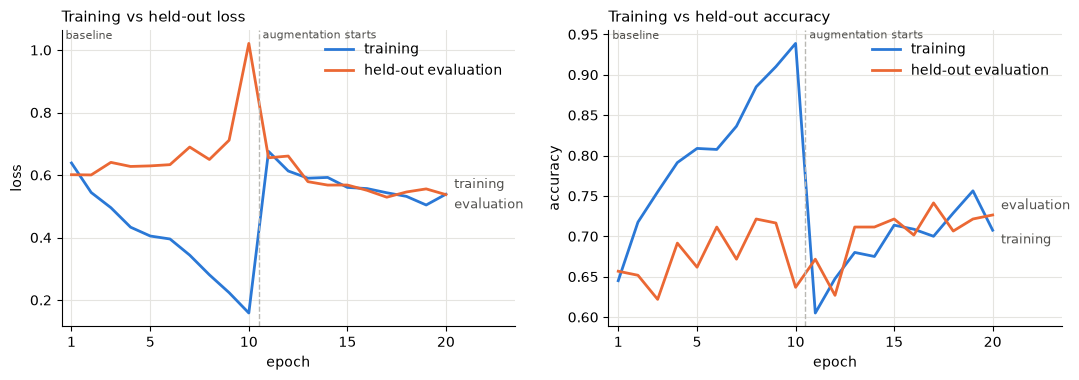

In [13]:
epochs = list(range(1, 2 * EPOCHS_PER_PHASE + 1))
series = {
    "loss": ("train_loss", "evaluation_loss", "loss"),
    "accuracy": ("train_accuracy", "evaluation_accuracy", "accuracy"),
}
BLUE, ORANGE, INK = "#2a78d6", "#eb6834", "#52514e"

fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
for ax, (title, (k_train, k_eval, ylabel)) in zip(axes, series.items()):
    train_values = baseline[k_train] + augmented[k_train]
    eval_values = baseline[k_eval] + augmented[k_eval]
    ax.plot(epochs, train_values, color=BLUE, linewidth=2, label="training")
    ax.plot(epochs, eval_values, color=ORANGE, linewidth=2, label="held-out evaluation")
    # direct labels at the line ends, nudged apart so they never overlap
    ends = sorted([("training", train_values[-1]), ("evaluation", eval_values[-1])], key=lambda t: t[1])
    for (name, value), dy in zip(ends, (-7, 7)):
        ax.annotate(name, (20, value), xytext=(6, dy), textcoords="offset points", va="center", fontsize=9, color=INK)
    ax.axvline(10.5, color="#b9b8b3", linewidth=1, linestyle="--")
    ax.text(10.7, ax.get_ylim()[1], "augmentation starts", fontsize=8, color=INK, va="top")
    ax.text(0.7, ax.get_ylim()[1], "baseline", fontsize=8, color=INK, va="top")
    ax.set_xlabel("epoch")
    ax.set_ylabel(ylabel)
    ax.set_title(f"Training vs held-out {title}", loc="left", fontsize=11)
    ax.set_xlim(0.5, 23.5)
    ax.set_xticks([1, 5, 10, 15, 20])
    ax.legend(frameon=False, loc="upper right")
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    ax.grid(color="#e5e4e0", linewidth=0.8)
    ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

**EN.** In the baseline phase the model overfits: training loss keeps falling (0.64 to 0.16) while the held-out loss
rises from 0.60 to 1.02 and accuracy stays between 0.62 and 0.72. With augmentation the training loss stops
falling so fast (0.54 in the last epoch), and the held-out loss improves to 0.54, with accuracy around 0.72. Augmentation made the
training task harder and the model memorise less; it did not make it much more accurate.
**PT.** Na fase base o modelo sofre overfitting: a perda de treino continua caindo (0.64 para 0.16) enquanto a perda de
avaliação sobe de 0.60 para 1.02 e a acurácia fica entre 0,62 e 0,72. Com augmentation a perda de treino deixa de cair tão
rápido (0.54 na última época) e a perda de avaliação melhora para 0.54, com acurácia em torno de 0,72. O augmentation tornou a tarefa de
treino mais difícil e o modelo memorizou menos; não o tornou muito mais acurado.

### Homework 8 — answers / respostas

| Question | Answer |
|---|---|
| Q1 Loss for the single-logit model | **`nn.BCEWithLogitsLoss()`** |
| Q2 Trainable parameters | **20073473** |
| Q3 Median baseline `train_accuracy` (2 decimals) | **0.81** |
| Q4 Population std of baseline `train_loss` (3 decimals) | **0.139** |
| Q5 Mean augmented `evaluation_loss` (3 decimals) | **0.575** |
| Q6 Mean of last five augmented `evaluation_accuracy` (2 decimals) | **0.72** |

### Notes / Observações

**EN.** 1) *Library versions.* The reference run is `torch==2.9.0+cpu`, `torchvision==0.24.0+cpu`, `numpy==2.3.3`,
`Pillow==11.3.0` on Python 3.11. The numbers quoted in the text above come from the run whose versions are printed in the
setup cell. 2) *Sensitivity checks.* The same reference script gives Q3 / Q4 / Q5 / Q6 = 0.81 / 0.139 / 0.575 / 0.72 on Python 3.13 and
0.81 / 0.139 / 0.575 / 0.72 with torch 2.8.0 (identical to the main run, 0.81 / 0.139 / 0.575 / 0.72). Two changes do move the numbers. Using 1 CPU thread instead of 2 (a different order of floating-point sums, which
mimics a different machine) gives Q3 / Q4 / Q5 / Q6 = 0.81 / 0.135 / 0.578 / 0.72, a shift of about 0.004 at most. Using seed 42 instead of 43 for the augmented loader
gives 0.593 for Q5 and 0.73 for Q6, and Q3 and Q4 do not move. Every shift stays inside the grader's tolerances (0.05 / 0.02 / 0.02 / 0.05), but
the seed shift in Q5 uses most of its 0.02 margin, which is why the homework fixes every seed.
3) *Small evaluation set.* The held-out split has 201 images, so one image is 0.5 percentage points of accuracy and the
standard error of an accuracy near 0.72 is about 3 points; differences of one or two points between epochs or phases are
within noise, and the loss curve is a more reliable guide than the accuracy curve. 4) *Single run.* Everything comes from
one seed; the homework fixes it on purpose so the answers can be compared, but it says little about run-to-run variation.

**PT.** 1) *Versões das bibliotecas.* A execução de referência usa `torch==2.9.0+cpu`, `torchvision==0.24.0+cpu`,
`numpy==2.3.3`, `Pillow==11.3.0` em Python 3.11. Os números citados no texto vêm da execução cujas versões aparecem na
célula de configuração. 2) *Testes de sensibilidade.* O mesmo script de referência dá Q3 / Q4 / Q5 / Q6 = 0.81 / 0.139 / 0.575 / 0.72 em Python 3.13 e
0.81 / 0.139 / 0.575 / 0.72 com torch 2.8.0 (idêntico à execução principal, 0.81 / 0.139 / 0.575 / 0.72). Duas mudanças alteram os números. Usar 1 thread de CPU em vez de 2 (outra ordem nas somas de ponto flutuante, o que imita
outra máquina) dá Q3 / Q4 / Q5 / Q6 = 0.81 / 0.135 / 0.578 / 0.72, uma mudança de cerca de 0,004 no máximo. Usar a semente 42 em vez de 43 no loader da fase com
augmentation dá 0.593 na Q5 e 0.73 na Q6, e Q3 e Q4 não mudam. Todas as variações ficam dentro das tolerâncias do corretor (0,05 / 0,02 / 0,02 / 0,05), mas a variação da
semente na Q5 consome a maior parte da margem de 0,02, e por isso o enunciado fixa todas as sementes.
3) *Conjunto de avaliação pequeno.* A divisão de avaliação tem 201 imagens, então uma imagem
vale 0,5 ponto percentual de acurácia e o erro-padrão de uma acurácia perto de 0,72 é cerca de 3 pontos; diferenças de um
ou dois pontos entre épocas ou fases estão dentro do ruído, e a curva de perda é um guia mais confiável do que a de
acurácia. 4) *Execução única.* Tudo vem de uma só semente; o enunciado a fixa de propósito para que as respostas sejam
comparáveis, mas isso diz pouco sobre a variação entre execuções.